## Introducción 

En este trabajo se estudia el filtrado digital de un ECG registrado durante una prueba de esfuerzo, con una frecuencia de muestreo de 1 kHz. La señal presenta interferencias de alta frecuencia asociadas al movimiento de los electrodos y la actividad muscular, además de variaciones lentas de la línea de base relacionadas, en parte, con la respiración.

El objetivo es reducir estas perturbaciones conservando la forma de los latidos. Para ello, se propone una plantilla pasabanda tomando como referencia el ancho de banda estimado previamente y se diseñan filtros IIR y FIR mediante distintas aproximaciones y métodos, utilizando Python y SciPy.

La comparación incluye las respuestas en módulo y fase, el retardo de grupo y el efecto del filtrado sobre regiones del ECG con distinta presencia de ruido. Así, se busca evaluar tanto la reducción de las interferencias como la conservación de la señal en los tramos menos contaminados.

**Análisis del ECG y definición de plantilla**

Para definir el filtrado se consideran dos tipos de perturbaciones: las variaciones lentas que desplazan la línea de base y las componentes de alta frecuencia que generan irregularidades en el trazado. Se busca reducir ambas sin modificar significativamente las ondas y los complejos del ECG.

Se propone una plantilla pasabanda con las siguientes regiones:
| Región | Intervalo |
|---|---|
| Rechazo inferior | 0 a 0,1 Hz |
| Transición inferior | 0,1 a 1 Hz |
| Banda de paso | 1 a 35 Hz |
| Transición superior | 35 a 50 Hz |
| Rechazo superior | 50 a 500 Hz |


El límite superior de paso se fijó en 35 Hz a partir del análisis realizado en la TS5, donde el 98 % de la potencia espectral del ECG se concentró por debajo de 28,23 Hz. Se dejó así un margen respecto de ese valor y se estableció el inicio del rechazo en 50 Hz, permitiendo una transición de 15 Hz.

En bajas frecuencias, se eligió una transición entre 0,1 y 1 Hz para reducir las variaciones de la línea de base. Esta elección se evaluará comparando los latidos antes y después del filtrado, para comprobar que no introduzca cambios importantes en su forma.

In [1]:
import numpy as np
from scipy import signal
import scipy.io as sio
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

Para establecer las especificaciones del filtrado, se definió una plantilla pasabanda que permite atenuar las componentes de baja frecuencia asociadas al desplazamiento de la línea de base y las componentes de alta frecuencia relacionadas con las interferencias musculares y el movimiento de los electrodos.

Se consideró una frecuencia de muestreo de 1000 Hz, correspondiente a una frecuencia de Nyquist de 500 Hz. La banda de paso se estableció entre 1 y 35 Hz, mientras que las bandas de rechazo se definieron entre 0 y 0,1 Hz y entre 50 y 500 Hz.

Además, se fijó una atenuación máxima de 3 dB en la banda de paso y una atenuación mínima de 40 dB en las bandas de rechazo. Estos parámetros constituyen las especificaciones que se utilizarán posteriormente para diseñar y comparar los filtros digitales.

In [4]:

fs_ecgconruido = 1000  # Hz

mat_struct = sio.loadmat("ECG_TP4.mat")
ecg_conruido = mat_struct["ecg_lead"].flatten()
t_ecgconruido = np.arange(len(ecg_conruido)) / fs_ecgconruido


#plantilla
wp = [1, 35]     # Hz  banda de paso
ws = [0.1, 50]  # Hz  rechazo: de 0 a 1 Hz (borde en 0.01 porque 0 exacto no se puede) y de 50 Hz en adelante
gpass = 3
gstop = 40

**Justificación de los parámetros de la plantilla**

La selección de las frecuencias de la plantilla se realizó considerando las características espectrales del ECG y las interferencias que se buscan reducir.

Para determinar el límite superior de la banda de paso se tomó como referencia el análisis realizado en la TS5, donde se estimó que el 98 % de la potencia espectral del ECG se concentraba por debajo de 28,23 Hz. A partir de este resultado, se estableció una frecuencia de paso superior de 35 Hz, dejando un margen para preservar las componentes relevantes de la señal. Asimismo, se fijó el comienzo de la banda de rechazo superior en 50 Hz, obteniendo una región de transición de 15 Hz.

En cuanto a las bajas frecuencias, se estableció una banda de rechazo entre 0 y 0,1 Hz, seguida de una región de transición hasta 1 Hz. Esta elección busca reducir las variaciones lentas de la línea de base, asociadas en parte a la respiración, procurando conservar la morfología de los latidos.

Finalmente, se adoptó una atenuación máxima de 3 dB en la banda de paso y una atenuación mínima de 40 dB en las bandas de rechazo. Estos valores establecen las tolerancias que deberán satisfacer los filtros diseñados y permiten comparar posteriormente sus respuestas en frecuencia.

### Diseño de los filtros IIR

Para el diseño de los filtros de respuesta impulsional infinita (IIR) se utilizó la función `iirdesign` de la biblioteca `scipy.signal`, que permite determinar los coeficientes del filtro a partir de las frecuencias de paso y rechazo y las especificaciones de atenuación establecidas previamente.

Se implementaron dos aproximaciones: Butterworth y Chebyshev tipo II. El filtro Butterworth se caracteriza por presentar una respuesta en módulo máximamente plana en la banda de paso, mientras que Chebyshev tipo II presenta una respuesta con oscilaciones controladas en la banda de rechazo, permitiendo obtener una transición más pronunciada bajo determinadas condiciones de diseño.

En ambos casos, los coeficientes se obtuvieron mediante una representación en secciones de segundo orden (SOS), con el objetivo de favorecer la estabilidad numérica de los filtros durante su implementación.

Además, se consideró que posteriormente se utilizaría la función `sosfiltfilt` para aplicar el filtrado hacia adelante y hacia atrás. Esta metodología permite obtener una respuesta efectiva de fase cero, evitando el desplazamiento temporal de las componentes del ECG, aunque modifica la respuesta en módulo respecto de una sola pasada.

Debido a que la aplicación en ambos sentidos eleva al cuadrado el módulo de la respuesta en frecuencia, las especificaciones de atenuación se dividieron por dos durante el diseño. De esta manera, se utilizaron valores de 1,5 dB para la banda de paso y 20 dB para las bandas de rechazo, buscando que la respuesta efectiva satisfaga las tolerancias originales de 3 dB y 40 dB.

Como tercera aproximación IIR se implementó un filtro Cauer o elíptico. A diferencia de Butterworth y Chebyshev tipo II, esta aproximación presenta oscilaciones controladas tanto en la banda de paso como en las bandas de rechazo, permitiendo obtener transiciones más pronunciadas para un determinado orden.

Para su diseño se utilizaron las mismas frecuencias de paso y rechazo establecidas en la plantilla. Asimismo, se dividieron por dos las especificaciones de atenuación, considerando que posteriormente se aplicará el filtrado bidireccional.

Al igual que los otros filtros IIR, se obtuvo una representación mediante secciones de segundo orden (SOS), con el objetivo de favorecer la estabilidad numérica. Además, se incorporó el cálculo del orden de los filtros para complementar la comparación entre las tres aproximaciones.

In [24]:
# FILTFILT

sos_butt = signal.iirdesign(wp, ws, gpass / 2, gstop / 2, ftype="butter", fs=fs_ecgconruido, output="sos")

sos_cheby = signal.iirdesign(
    wp=wp,
    ws=ws,
    gpass=gpass / 2,
    gstop=gstop / 2,
    ftype="cheby2",
    output="sos",
    fs=fs_ecgconruido
)

# Filtro IIR Cauer (elíptico)
sos_elip = signal.iirdesign(wp, ws, gpass / 2, gstop / 2, ftype="ellip", fs=fs_ecgconruido, output="sos")

print(f"IIR Butterworth: orden {2 * sos_butt.shape[0]}")
print(f"IIR Chebyshev II: orden {2 * sos_cheby.shape[0]}")
print(f"IIR Cauer (elíptico): orden {2 * sos_elip.shape[0]}")

IIR Butterworth: orden 16
IIR Chebyshev II: orden 8
IIR Cauer (elíptico): orden 6


### Diseño de los filtros FIR

Para complementar el análisis se diseñaron dos filtros de respuesta impulsional finita (FIR), utilizando el método de ventanas y el método de cuadrados mínimos ponderados. A diferencia de los filtros IIR, los FIR implementados presentan una respuesta impulsional de duración finita y permiten obtener una fase lineal mediante coeficientes simétricos.

El primer diseño se realizó utilizando la función `firwin2` de `scipy.signal`, junto con una ventana Hamming. Esta metodología permite aproximar una respuesta en frecuencia definida a partir de un conjunto de frecuencias y ganancias deseadas. La aplicación de la ventana busca reducir las oscilaciones producidas por el truncamiento de la respuesta impulsional.

Para este filtro se establecieron 2001 coeficientes y una banda de paso entre 1 y 35 Hz. La transición superior se definió entre 35 y 40 Hz, utilizando un ancho de transición de 5 Hz. Esta elección permite plantear una atenuación más rápida que la exigida inicialmente por la plantilla, cuyo rechazo superior comienza en 50 Hz.

El segundo diseño se realizó mediante la función `firls`, basada en el método de cuadrados mínimos ponderados (WLS). Este procedimiento determina los coeficientes del filtro minimizando el error cuadrático entre la respuesta deseada y la obtenida, considerando los pesos asignados a las distintas bandas de frecuencia.

En este caso, se utilizaron pesos elevados en las bandas de rechazo, con el propósito de priorizar la atenuación de las componentes interferentes, mientras que en la región de transición superior se asignó un peso reducido para permitir mayor flexibilidad en el ajuste.

Al igual que en el diseño anterior, se emplearon 2001 coeficientes, obteniendo un filtro FIR de fase lineal. Esta característica permite conservar las relaciones temporales entre las componentes frecuenciales del ECG, aunque introduce un retardo constante que deberá compensarse al comparar las señales filtradas.

Como tercera metodología de diseño FIR se utilizó el algoritmo Parks-McClellan, implementado mediante la función `remez` de `scipy.signal`. Este método permite obtener filtros que aproximan una respuesta en frecuencia deseada minimizando el máximo error ponderado en las bandas especificadas.

Para construir el filtro pasabanda se diseñaron dos filtros FIR independientes. El primero corresponde a un pasaaltos, con una banda de rechazo hasta 0,1 Hz y una banda de paso a partir de 1 Hz. El segundo corresponde a un pasabajos, con una banda de paso hasta 35 Hz y una banda de rechazo desde 50 Hz.

Posteriormente, se combinaron ambos filtros mediante la convolución de sus respuestas impulsionales, operación equivalente a conectarlos en cascada. De esta manera, se obtuvo una respuesta pasabanda que busca atenuar tanto las componentes de baja frecuencia como las de alta frecuencia presentes en el ECG.

Para el diseño del pasaaltos se utilizaron 2001 coeficientes, mientras que para el pasabajos se emplearon 201 coeficientes. Como resultado de la convolución se obtuvo un filtro FIR de 2201 coeficientes.

Debido a la simetría de las respuestas impulsionales, el filtro resultante presenta fase lineal y un retardo de grupo constante de 1100 muestras, equivalente a 1,1 segundos para la frecuencia de muestreo utilizada.

Este diseño se incorporó para comparar el comportamiento del método Parks-McClellan con los filtros FIR obtenidos mediante ventana Hamming y cuadrados mínimos ponderados, considerando posteriormente sus respuestas en frecuencia y su efecto sobre el registro electrocardiográfico.

In [25]:

# FIR (Ventanas + Cuadrados Mínimos WLS) - PASABANDA

delta_w = 5
f_nyq = fs_ecgconruido / 2
gains = [0.0, 0.0, 1.0, 1.0, 0.0, 0.0]

freqs_hamming = [0.0, ws[0], wp[0], wp[1], wp[1] + delta_w, f_nyq]
b_win_hamming = signal.firwin2(2001, freqs_hamming, gains, window="hamming", fs=fs_ecgconruido)

bands_wls = [0.0, ws[0],  #rechazo inferior
             wp[0], wp[1], #paso
             wp[1],ws[1], #transición superior
             ws[1],f_nyq]  #rechazo superior

desired_wls = [0.0, 0.0,   #rechazo inferior ganancia 0
               1.0, 1.0,   #paso ganancia 1
               1.0, 0.0,   #trancision el descenso lineal deseado
               0.0,0.0]

weights_wls = [1000.0,
               1.0,
               0.01,      #en la transición prioridad pequeña
               1000.0]
b_wls = signal.firls(2001, bands_wls, desired_wls, weight=weights_wls, fs=fs_ecgconruido)


b_remez_pa = signal.remez(2001,
                          [0.0, ws[0], wp[0], f_nyq],   # rechazo | paso
                          [0.0, 1.0],
                          weight=[10.0, 1.0],
                          fs=fs_ecgconruido,
                          grid_density=16)

b_remez_pb = signal.remez(201,
                          [0.0, wp[1], ws[1], f_nyq],   # paso | rechazo
                          [1.0, 0.0],
                          weight=[1.0, 10.0],
                          fs=fs_ecgconruido)

b_remez = np.convolve(b_remez_pa, b_remez_pb)

print(f"FIR hamming diseñado: {len(b_win_hamming)} coeficientes")
print(f"FIR WLS (firls) diseñado: {len(b_wls)} coeficientes")


FIR hamming diseñado: 2001 coeficientes
FIR WLS (firls) diseñado: 2001 coeficientes


### Análisis de la respuesta en frecuencia

Una vez diseñados los seis filtros digitales, se calcularon sus respuestas en frecuencia con el objetivo de analizar su comportamiento y verificar el cumplimiento de las especificaciones establecidas en la plantilla de diseño.

Para ello, se utilizó una grilla común de frecuencias, formada por 65536 puntos distribuidos logarítmicamente entre 0,0001 Hz y la frecuencia de Nyquist de 500 Hz, incorporando además la frecuencia nula. Esta distribución permite obtener una mayor concentración de puntos en las bajas frecuencias, donde se encuentra una de las regiones de transición de la plantilla.

Las respuestas de los filtros FIR Hamming, WLS y Parks-McClellan se calcularon mediante la función `freqz`, mientras que para los filtros IIR Butterworth, Chebyshev II y Cauer se utilizó `sosfreqz`, debido a su implementación mediante secciones de segundo orden.

En todos los casos, los módulos se expresaron en decibeles para facilitar la comparación con las especificaciones de atenuación.

Para los filtros IIR se consideró la respuesta efectiva correspondiente al filtrado bidireccional, cuyo módulo equivale al cuadrado del correspondiente a una sola pasada. En cambio, para los FIR se consideró la respuesta de una única pasada.

In [26]:

#%% Calcular las respuestas antes de graficarlas

# Grilla logarítmica común para todos los filtros
frecuencias = np.concatenate((
    [0.0],
    np.logspace(
        np.log10(0.0001),
        np.log10(fs_ecgconruido / 2),
        num=65536
    )
))

# FIR Hamming
f_hamm, h_hamm = signal.freqz(b_win_hamming, a=1, worN=frecuencias, fs=fs_ecgconruido)
modulo_hamm_db = 20 * np.log10(np.maximum(np.abs(h_hamm), 1e-12))
fase_hamm = np.unwrap(np.angle(h_hamm))

# FIR mínimos cuadrados
f_wls, h_wls = signal.freqz(b_wls, a=1, worN=frecuencias, fs=fs_ecgconruido)
modulo_wls_db = 20 * np.log10(np.maximum(np.abs(h_wls), 1e-12))
fase_wls = np.unwrap(np.angle(h_wls))

# FIR Parks-McClellan
f_remez, h_remez = signal.freqz(b_remez, a=1, worN=frecuencias, fs=fs_ecgconruido)
modulo_remez_db = 20 * np.log10(np.maximum(np.abs(h_remez), 1e-12))
fase_remez = np.unwrap(np.angle(h_remez))

# IIR Butterworth
f_butt, h_butt = signal.sosfreqz(sos_butt, worN=frecuencias, fs=fs_ecgconruido)
# Respuesta efectiva de sosfiltfilt
modulo_butt_db = 20 * np.log10(np.maximum(np.abs(h_butt)**2, 1e-12))
# Fase de una pasada
fase_butt = np.unwrap(np.angle(h_butt))

# IIR Chebyshev II
f_cheby, h_cheby = signal.sosfreqz(sos_cheby, worN=frecuencias, fs=fs_ecgconruido)
modulo_cheby_db = 20 * np.log10(np.maximum(np.abs(h_cheby)**2, 1e-12))

# IIR Cauer
f_elip, h_elip = signal.sosfreqz(sos_elip, worN=frecuencias, fs=fs_ecgconruido)
modulo_elip_db = 20 * np.log10(np.maximum(np.abs(h_elip)**2, 1e-12))



In [22]:

# Comparar ambas grillas sobre el MISMO gráfico de módulo

f_pocos = np.linspace(
    0, fs_ecgconruido / 2,
    8192, endpoint=False
)

f_detalle = np.logspace(
    np.log10(0.0001),
    np.log10(fs_ecgconruido / 2),
    65536
)

filtros_comparar = [
    ("IIR Butterworth", sos_butt, "iir", "red"),
    ("FIR Hamming", b_win_hamming, "fir", "crimson"),
    ("FIR WLS", b_wls, "fir", "darkmagenta")
]

for nombre, coeficientes, tipo, color in filtros_comparar:

    if tipo == "iir":

        _, h_pocos = signal.sosfreqz(
            coeficientes, worN=f_pocos, fs=fs_ecgconruido
        )

        _, h_detalle = signal.sosfreqz(
            coeficientes, worN=f_detalle, fs=fs_ecgconruido
        )

        # Módulo efectivo de sosfiltfilt
        amplitud_pocos = np.abs(h_pocos)**2
        amplitud_detalle = np.abs(h_detalle)**2

    else:

        _, h_pocos = signal.freqz(
            coeficientes, worN=f_pocos, fs=fs_ecgconruido
        )

        _, h_detalle = signal.freqz(
            coeficientes, worN=f_detalle, fs=fs_ecgconruido
        )

        amplitud_pocos = np.abs(h_pocos)
        amplitud_detalle = np.abs(h_detalle)

    db_pocos = 20 * np.log10(
        np.maximum(amplitud_pocos, 1e-12)
    )

    db_detalle = 20 * np.log10(
        np.maximum(amplitud_detalle, 1e-12)
    )

    ax.plot(
        f_detalle, db_detalle,
        color=color,
        linewidth=1.6,
        label=f"{nombre} — grilla logarítmica"
    )

    # Mostrar los puntos originales solo cerca de las transiciones
    seleccion = (
        (f_pocos <= wp[0] + 0.5)
        |
        (
            (f_pocos >= wp[1] - 1)
            & (f_pocos <= ws[1] + 1)
        )
    )

    ax.plot(
        f_pocos[seleccion],
        db_pocos[seleccion],
        linestyle="none",
        marker="o",
        markersize=4,
        markerfacecolor="none",
        markeredgecolor="black",
        label=(
            "Puntos de grilla uniforme"
            if tipo == "iir" else "_nolegend_"
        )
    )


Con el objetivo de comparar las distintas metodologías de diseño, se representaron conjuntamente las respuestas en módulo de los seis filtros digitales, incorporando las regiones prohibidas definidas por la plantilla de tolerancia.

Estas regiones permiten identificar los valores de frecuencia y atenuación que los filtros deben respetar para satisfacer las especificaciones establecidas. En particular, se considera una atenuación máxima de 3 dB en la banda de paso comprendida entre 1 y 35 Hz, y una atenuación mínima de 40 dB en las bandas de rechazo.

La representación conjunta permite comparar las características de las tres aproximaciones IIR y de los tres métodos FIR, especialmente en las regiones de transición, y evaluar cualitativamente el cumplimiento de las especificaciones de diseño.

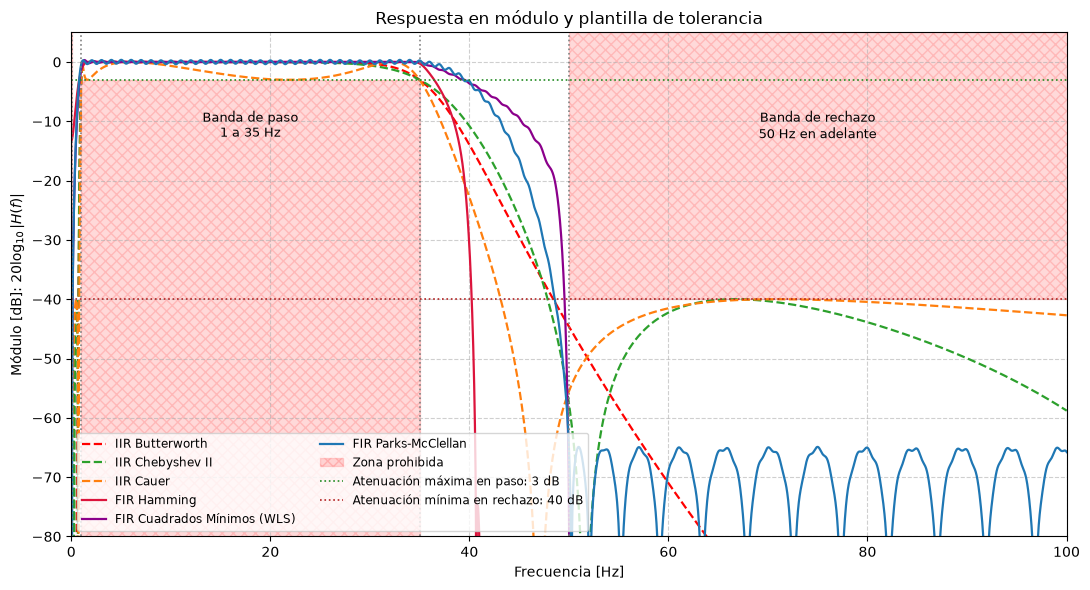

In [27]:

# respuesta en modulo

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(f_butt, modulo_butt_db, label="IIR Butterworth", color="red", linestyle="--", lw=1.6)
ax.plot(f_cheby, modulo_cheby_db, label="IIR Chebyshev II", color="tab:green", linestyle="--", lw=1.6)
ax.plot(f_elip, modulo_elip_db, label="IIR Cauer", color="tab:orange", linestyle="--", lw=1.6)
ax.plot(f_hamm, modulo_hamm_db, label="FIR Hamming", color="crimson", linestyle="-", lw=1.6)
ax.plot(f_wls, modulo_wls_db, label="FIR Cuadrados Mínimos (WLS)", color="darkmagenta", linestyle="-", lw=1.6)
ax.plot(f_remez, modulo_remez_db, label="FIR Parks-McClellan", color="tab:blue", linestyle="-", lw=1.6)

f_max = fs_ecgconruido / 2
y_min = -100
y_max = 5

# Zona prohibida de la banda de paso: por debajo de -gpass dB, entre wp[0] y wp[1]
rect_pasante = Rectangle((wp[0], y_min), wp[1] - wp[0], -gpass - y_min, facecolor="red", alpha=0.15, edgecolor="red", hatch="xxx", lw=1.0, label="Zona prohibida")

# Zona prohibida de rechazo inferior: por encima de -gstop dB, de 0 a ws[0]
rect_rechazo_inf = Rectangle((0, -gstop), ws[0], y_max + gstop, facecolor="red", alpha=0.15, edgecolor="red", hatch="xxx", lw=1.0)

# Zona prohibida de rechazo superior: por encima de -gstop dB, de ws[1] en adelante
rect_rechazo_sup = Rectangle((ws[1], -gstop), f_max - ws[1], y_max + gstop, facecolor="red", alpha=0.15, edgecolor="red", hatch="xxx", lw=1.0)

ax.add_patch(rect_pasante)
ax.add_patch(rect_rechazo_inf)
ax.add_patch(rect_rechazo_sup)

# Bordes de las cuatro bandas
ax.axvline(ws[0], color="gray", linestyle=":", lw=1.2)
ax.axvline(wp[0], color="gray", linestyle=":", lw=1.2)
ax.axvline(wp[1], color="gray", linestyle=":", lw=1.2)
ax.axvline(ws[1], color="gray", linestyle=":", lw=1.2)

ax.axhline(-gpass, color="forestgreen", linestyle=":", lw=1.2, label=f"Atenuación máxima en paso: {gpass} dB")
ax.axhline(-gstop, color="firebrick", linestyle=":", lw=1.2, label=f"Atenuación mínima en rechazo: {gstop} dB")

ax.set_xlim(0, 100)
ax.set_ylim(-80, y_max)
ax.set_title("Respuesta en módulo y plantilla de tolerancia")
ax.set_xlabel("Frecuencia [Hz]")
ax.set_ylabel(r"Módulo [dB]: $20\log_{10}|H(f)|$")
ax.grid(True, linestyle="--", alpha=0.6)

ax.text((wp[0] + wp[1]) / 2, -8, f"Banda de paso\n{wp[0]} a {wp[1]} Hz", ha="center", va="top", fontsize=9)
ax.text((ws[1] + 100) / 2, -8, f"Banda de rechazo\n{ws[1]} Hz en adelante", ha="center", va="top", fontsize=9)

ax.legend(loc="lower left", fontsize=8.5, ncol=2)
fig.tight_layout()
plt.show()



**Figura 1.** Comparación de las respuestas en módulo de los seis filtros digitales diseñados y de las regiones prohibidas establecidas por la plantilla de tolerancia.

### Análisis de las respuestas en módulo

En la Figura 1 se presentan las respuestas en módulo de los seis filtros digitales diseñados, junto con las regiones prohibidas establecidas por la plantilla de tolerancia. En todos los casos se observa un comportamiento pasabanda, aunque existen diferencias relacionadas con las aproximaciones y los métodos de diseño empleados.

En la banda de paso, comprendida entre 1 y 35 Hz, la mayoría de los filtros presentan respuestas próximas a 0 dB, lo que indica una baja atenuación de las componentes frecuenciales de interés. El filtro Butterworth muestra una respuesta suave y sin oscilaciones apreciables, mientras que Chebyshev tipo II conserva un comportamiento similar en gran parte de esta región. Por su parte, el filtro Cauer presenta variaciones del módulo propias de la aproximación elíptica, con oscilaciones más evidentes dentro de la banda de paso.

En cuanto a los filtros FIR, Hamming y WLS mantienen respuestas aproximadamente planas en gran parte del intervalo de interés, mientras que Parks-McClellan presenta pequeñas oscilaciones asociadas al criterio de aproximación utilizado.

Las principales diferencias se observan en la transición superior, comprendida entre 35 y 50 Hz. El filtro FIR Hamming presenta una caída pronunciada alrededor de 40 Hz, mientras que WLS y Parks-McClellan muestran transiciones más graduales, alcanzando niveles elevados de atenuación al aproximarse a la banda de rechazo.

Por otra parte, los filtros IIR presentan comportamientos característicos de sus respectivas aproximaciones. Butterworth muestra una disminución progresiva del módulo, Chebyshev tipo II presenta una transición más pronunciada y Cauer exhibe variaciones asociadas a su respuesta elíptica.

En la banda de rechazo superior, los filtros FIR alcanzan atenuaciones elevadas, destacándose las oscilaciones de Parks-McClellan, características del método de diseño. Los filtros Chebyshev II y Cauer también presentan variaciones del módulo en esta región, con niveles próximos o inferiores a los límites establecidos por la plantilla.

En conjunto, la comparación permite observar que los seis filtros responden al comportamiento pasabanda buscado, aunque presentan diferencias en la planicidad de la banda de paso, las regiones de transición y los niveles de atenuación. Si bien el gráfico permite realizar una evaluación cualitativa de las respuestas, para confirmar rigurosamente el cumplimiento de las tolerancias sería necesario verificar numéricamente los valores alcanzados en cada banda, especialmente en las regiones próximas a sus límites.

### Análisis de la respuesta en fase

Además de estudiar las respuestas en módulo, se analizaron las características de fase de los tres filtros FIR diseñados: Hamming, cuadrados mínimos ponderados (WLS) y Parks-McClellan. Este análisis resulta importante debido a que las modificaciones de fase pueden alterar las relaciones temporales entre las componentes frecuenciales del ECG y, en consecuencia, afectar su morfología.

Para ello, se calcularon las fases a partir de las respuestas en frecuencia obtenidas previamente, utilizando la función `unwrap` para facilitar su representación.

Los tres filtros presentan coeficientes simétricos, propiedad que permite obtener una respuesta de fase lineal y un retardo de grupo constante. En el caso de Hamming y WLS, ambos fueron diseñados con 2001 coeficientes, por lo que presentan un retardo de 1000 muestras, equivalente a 1 segundo.

Por su parte, el filtro Parks-McClellan se obtuvo mediante la combinación de dos filtros FIR, dando como resultado una respuesta impulsional de 2201 coeficientes. En consecuencia, su retardo de grupo es de 1100 muestras, equivalente a 1,1 segundos.

Estas diferencias permiten anticipar que las respuestas de Hamming y WLS tendrán pendientes de fase similares, mientras que Parks-McClellan presentará una pendiente de mayor magnitud. Los retardos correspondientes deberán compensarse posteriormente para comparar temporalmente las señales filtradas con el ECG original.

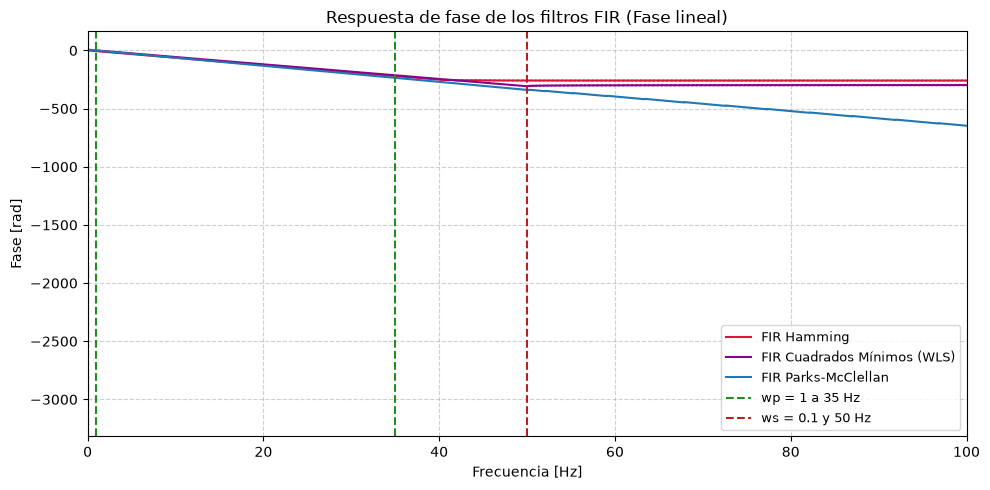

In [29]:

# %%
# respuesta en fase

plt.figure(figsize=(10, 5))

# Graficamos solo los filtros FIR (los IIR con sosfiltfilt tienen fase cero)
plt.plot(f_hamm, fase_hamm, label="FIR Hamming", color="crimson", lw=1.5)
plt.plot(f_wls, fase_wls, label="FIR Cuadrados Mínimos (WLS)", color="darkmagenta", lw=1.5)
plt.plot(f_remez, fase_remez, label="FIR Parks-McClellan", color="tab:blue", lw=1.5)

plt.axvline(wp[0], color="forestgreen", linestyle="--", label=f"wp = {wp[0]} a {wp[1]} Hz")
plt.axvline(wp[1], color="forestgreen", linestyle="--")
plt.axvline(ws[0], color="firebrick", linestyle="--", label=f"ws = {ws[0]} y {ws[1]} Hz")
plt.axvline(ws[1], color="firebrick", linestyle="--")

plt.xlim(0, 100)
plt.title("Respuesta de fase de los filtros FIR (Fase lineal)")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Fase [rad]")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="best", fontsize=9)
plt.tight_layout()
plt.show()


**Figura 2.** Comparación de las respuestas en fase de los filtros FIR Hamming, cuadrados mínimos ponderados (WLS) y Parks-McClellan.

**Análisis de los resultados**

En la Figura 2 se presentan las respuestas en fase de los filtros FIR Hamming, WLS y Parks-McClellan. Dentro de la banda de paso, comprendida entre 1 y 35 Hz, se observa que las tres curvas presentan una disminución aproximadamente lineal de la fase a medida que aumenta la frecuencia, comportamiento característico de los filtros FIR de fase lineal.

Las respuestas correspondientes a Hamming y WLS presentan pendientes prácticamente iguales, debido a que ambos fueron diseñados con 2001 coeficientes y poseen un retardo de grupo constante de 1000 muestras, equivalente a 1 segundo.

Por su parte, el filtro Parks-McClellan presenta una pendiente de mayor magnitud, lo que resulta coherente con sus 2201 coeficientes y su retardo de grupo de 1100 muestras, equivalente a 1,1 segundos.

Al ingresar en las regiones de rechazo, las respuestas de Hamming y WLS dejan de presentar una evolución lineal evidente y aparecen pequeñas variaciones. Este comportamiento se asocia a las frecuencias donde el módulo de la respuesta se aproxima a cero, por lo que la fase resulta poco representativa y su desenvolvimiento puede generar discontinuidades aparentes.

En cambio, Parks-McClellan mantiene una evolución aproximadamente lineal en una región más amplia del espectro, aunque la fase en las frecuencias fuertemente atenuadas tiene escasa relevancia para la señal filtrada.

En conjunto, los resultados permiten identificar el comportamiento de fase lineal de los tres filtros FIR y relacionar las diferencias en sus pendientes con los retardos de grupo correspondientes. Esta propiedad resulta favorable para preservar las relaciones temporales entre las componentes frecuenciales del ECG, siempre que se considere la compensación de los retardos introducidos por el filtrado.

### Análisis de la respuesta al impulso

Con el objetivo de complementar el estudio de las características temporales de los filtros FIR, se representaron sus respuestas al impulso. Estas permiten observar la distribución de los coeficientes y analizar su simetría, propiedad relacionada directamente con el comportamiento de fase lineal.

Ambos filtros fueron diseñados con 2001 coeficientes, obteniéndose respuestas impulsionales de duración finita y simétricas respecto de su punto central. Esta característica permite que las componentes frecuenciales experimenten un retardo de grupo constante, evitando introducir una distorsión de fase relativa entre las componentes que atraviesan el filtro.

A partir de la cantidad de coeficientes y de la frecuencia de muestreo de 1000 Hz, se calculó un retardo de 1000 muestras, equivalente a 1 segundo para ambos filtros.

En los gráficos se representaron las respuestas impulsionales correspondientes a Hamming y WLS, señalando mediante una línea vertical la posición de su retardo de grupo. Este valor será considerado posteriormente para compensar el desplazamiento temporal introducido por los filtros al comparar las señales de ECG.

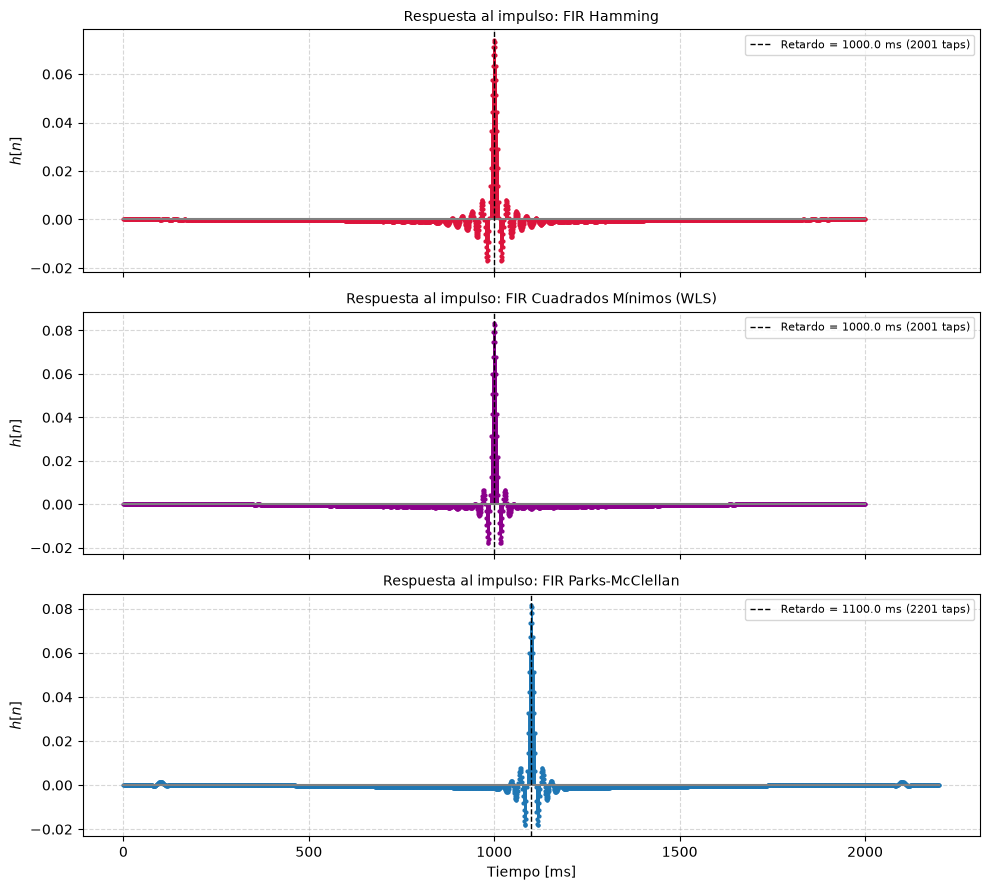

In [30]:

# %%
# impulso

filtros_fir = [
    ("FIR Hamming", b_win_hamming, "crimson"),
    ("FIR Cuadrados Mínimos (WLS)", b_wls, "darkmagenta"),
    ("FIR Parks-McClellan", b_remez, "tab:blue"),
]

fig, axs = plt.subplots(len(filtros_fir), 1, figsize=(10, 9), sharex=True)

for eje, (nombre, b, color) in zip(axs, filtros_fir):
    n_taps = len(b)
    t_ms = (np.arange(n_taps) / fs_ecgconruido) * 1000
    markerline, stemlines, baseline = eje.stem(
        t_ms, b, linefmt=color, markerfmt="o", basefmt="gray"
    )
    plt.setp(markerline, markersize=2, color=color)
    plt.setp(stemlines, linewidth=0.7, color=color)

    tau_ms = ((n_taps - 1) / 2) / fs_ecgconruido * 1000
    eje.axvline(
        tau_ms, color="black", linestyle="--", lw=1.0,
        label=f"Retardo = {tau_ms:.1f} ms ({n_taps} taps)"
    )
    eje.set_title(f"Respuesta al impulso: {nombre}", fontsize=10)
    eje.set_ylabel(r"$h[n]$")
    eje.grid(True, linestyle="--", alpha=0.5)
    eje.legend(loc="upper right", fontsize=8)

axs[-1].set_xlabel("Tiempo [ms]")

fig.tight_layout()
plt.show()

**Figura 3.** Respuestas al impulso de los filtros FIR Hamming, WLS y Parks-McClellan, con indicación del retardo de grupo correspondiente a cada diseño.

**Análisis de los resultados**

En la Figura 3 se presentan las respuestas al impulso de los tres filtros FIR diseñados mediante ventana Hamming, cuadrados mínimos ponderados (WLS) y Parks-McClellan.

En los tres casos se observa una distribución simétrica de los coeficientes respecto de su punto central, lo que resulta consistente con el comportamiento de fase lineal analizado anteriormente. Para los filtros Hamming y WLS, el centro de simetría se encuentra en 1000 ms, mientras que para Parks-McClellan se ubica en 1100 ms.

Las respuestas presentan sus coeficientes de mayor amplitud concentrados alrededor del centro, acompañados de oscilaciones cuyos valores disminuyen al alejarse de este. No obstante, se observan diferencias en la distribución de los coeficientes asociadas a las distintas metodologías de diseño.

El filtro Hamming presenta oscilaciones relativamente extendidas alrededor del coeficiente central, mientras que WLS muestra una mayor concentración de los coeficientes de amplitud elevada en la zona central. Por su parte, Parks-McClellan presenta una distribución central semejante, aunque también se distinguen pequeños coeficientes alejados del centro de simetría.

En cuanto al retardo de grupo, los filtros Hamming y WLS presentan un valor constante de 1000 muestras, equivalente a 1 segundo, mientras que Parks-McClellan posee un retardo de 1100 muestras, equivalente a 1,1 segundos.

Esta diferencia se debe a la mayor cantidad de coeficientes del filtro Parks-McClellan, obtenida mediante la convolución de los dos filtros FIR utilizados en su construcción.

En conjunto, los resultados permiten verificar la simetría de las respuestas impulsionales y relacionarla con el comportamiento de fase lineal de los tres filtros. Asimismo, los retardos identificados deberán compensarse durante la comparación temporal de las señales filtradas con el ECG original.

### Aplicación de los filtros al registro de ECG

Una vez analizadas las características de los filtros diseñados, se procedió a aplicarlos sobre el registro electrocardiográfico original, con el objetivo de evaluar su capacidad para reducir las interferencias presentes en la señal y conservar la morfología característica de los latidos.

Para los filtros IIR Butterworth, Chebyshev tipo II y Cauer se utilizó la función `sosfiltfilt` de `scipy.signal`, que realiza el filtrado hacia adelante y hacia atrás. Este procedimiento permite obtener una respuesta efectiva de fase cero, evitando el desplazamiento temporal neto asociado a la fase de los filtros. Sin embargo, debido a la doble aplicación, el módulo de la respuesta resultante se eleva al cuadrado, efecto que fue considerado previamente durante el diseño.

En cambio, los filtros FIR Hamming, WLS y Parks-McClellan se aplicaron mediante la función `lfilter`, que realiza el filtrado en una única dirección. Debido a la simetría de sus respuestas impulsionales, estos filtros presentan fase lineal y un retardo de grupo constante.

En los filtros Hamming y WLS, diseñados con 2001 coeficientes, se obtuvo un retardo de 1000 muestras, equivalente a 1 segundo. Por su parte, Parks-McClellan, con 2201 coeficientes, presentó un retardo de 1100 muestras, equivalente a 1,1 segundos.

Para realizar una comparación temporal adecuada, se calcularon las demoras correspondientes a cada filtro FIR, que posteriormente se utilizaron para alinear sus salidas con el ECG original. De esta manera, las diferencias observadas entre las señales pueden analizarse sin confundirlas con los desplazamientos temporales introducidos por los filtros.

In [31]:

#%%
# filtros

# iir (fase cero)
ecg_filt_butt = signal.sosfiltfilt(sos_butt, ecg_conruido)
ecg_filt_cheby = signal.sosfiltfilt(sos_cheby, ecg_conruido)
ecg_filt_elip = signal.sosfiltfilt(sos_elip, ecg_conruido)

# fir (causales, con retardo)
ecg_filt_winhamm = signal.lfilter(b_win_hamming, 1, ecg_conruido)
ecg_filt_wls = signal.lfilter(b_wls, 1, ecg_conruido)
ecg_filt_remez = signal.lfilter(b_remez, 1, ecg_conruido)

# retardos fir en muestras
demora_hamm = (b_win_hamming.shape[0] - 1) // 2
demora_wls = (b_wls.shape[0] - 1) // 2
demora_remez = (b_remez.shape[0] - 1) // 2


### Comparación temporal de las señales filtradas

Para evaluar el efecto de los seis filtros sobre el registro electrocardiográfico, se seleccionó un intervalo comprendido entre las muestras 300000 y 312000, equivalente a 12 segundos de señal.

En esta región se representaron conjuntamente el ECG original y las señales filtradas mediante las tres aproximaciones IIR y los tres métodos FIR. Con el objetivo de facilitar la visualización y evitar la superposición excesiva de las curvas, se realizaron dos representaciones independientes, manteniendo el mismo intervalo temporal y la misma escala de amplitud.

En los filtros FIR se compensaron los retardos correspondientes a cada diseño, permitiendo alinear temporalmente las señales con el ECG original. Por su parte, los filtros IIR fueron aplicados mediante filtrado bidireccional, evitando un desplazamiento temporal neto asociado a su fase.

Esta comparación permite evaluar cualitativamente el efecto de las distintas metodologías sobre la suavidad del trazado, el comportamiento de la línea de base y la conservación de la morfología de los complejos cardíacos.

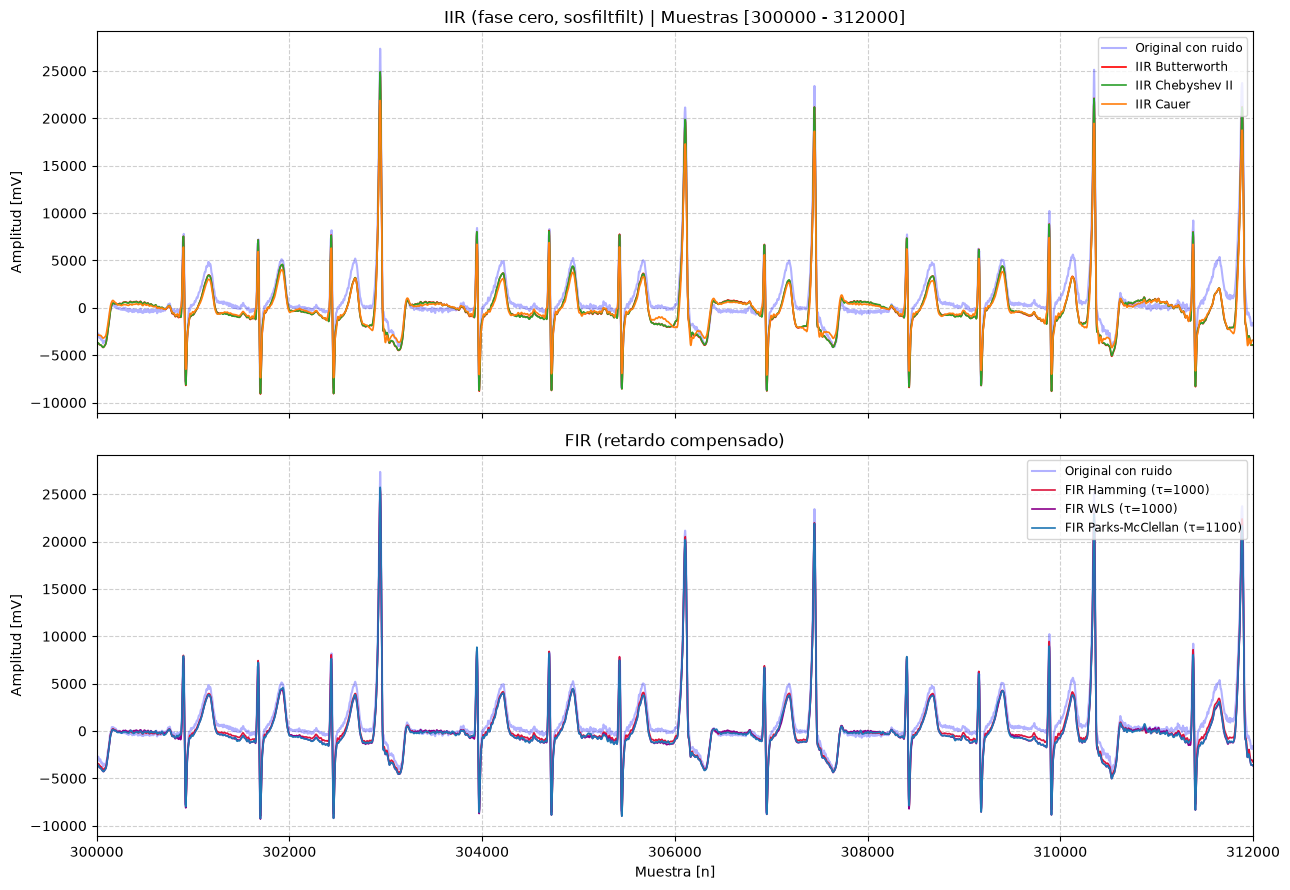

In [32]:

#%%
# original vs 3 iir vs 3 fir

# Rango de visualización en muestras
n_1 = 300000
n_2 = 312000

# Segmentos de las señales para la ventana de visualización
seg_orig = ecg_conruido[n_1:n_2]

# Segmentos IIR (retardo = 0 por sosfiltfilt)
seg_butt = ecg_filt_butt[n_1:n_2]
seg_cheby = ecg_filt_cheby[n_1:n_2]
seg_elip = ecg_filt_elip[n_1:n_2]

# Segmentos FIR (compensados con sus respectivas demoras)
seg_hamm = ecg_filt_winhamm[n_1 + demora_hamm : n_2 + demora_hamm]
seg_wls = ecg_filt_wls[n_1 + demora_wls : n_2 + demora_wls]
seg_remez = ecg_filt_remez[n_1 + demora_remez : n_2 + demora_remez]

# Eje de muestras común para la ventana
n_eje = np.arange(n_1, n_2)

# Gráfico: IIR arriba, FIR abajo, para que no se tapen las 6 curvas
fig, (ax_iir, ax_fir) = plt.subplots(2, 1, figsize=(13, 9), sharex=True, sharey=True)

ax_iir.plot(n_eje, seg_orig, label="Original con ruido", color="blue", lw=1.5, alpha=0.3)
ax_iir.plot(n_eje, seg_butt, label="IIR Butterworth", color="red", lw=1.2)
ax_iir.plot(n_eje, seg_cheby, label="IIR Chebyshev II", color="tab:green", lw=1.2)
ax_iir.plot(n_eje, seg_elip, label="IIR Cauer", color="tab:orange", lw=1.2)
ax_iir.set_title(f"IIR (fase cero, sosfiltfilt) | Muestras [{n_1} - {n_2}]")

ax_fir.plot(n_eje, seg_orig, label="Original con ruido", color="blue", lw=1.5, alpha=0.3)
ax_fir.plot(n_eje, seg_hamm, label=f"FIR Hamming (τ={demora_hamm})", color="crimson", lw=1.2)
ax_fir.plot(n_eje, seg_wls, label=f"FIR WLS (τ={demora_wls})", color="darkmagenta", lw=1.2)
ax_fir.plot(n_eje, seg_remez, label=f"FIR Parks-McClellan (τ={demora_remez})", color="tab:blue", lw=1.2)
ax_fir.set_title("FIR (retardo compensado)")
ax_fir.set_xlabel("Muestra [n]")

for eje in (ax_iir, ax_fir):
    eje.set_ylabel("Amplitud [mV]")
    eje.set_xlim(n_1, n_2)
    eje.grid(True, linestyle="--", alpha=0.6)
    eje.legend(loc="upper right", fontsize=8.5)

fig.tight_layout()
plt.show()


**Figura 4.** Comparación temporal entre el ECG original y las señales filtradas mediante las tres aproximaciones IIR (Butterworth, Chebyshev II y Cauer) y los tres métodos FIR (Hamming, WLS y Parks-McClellan), considerando el intervalo de muestras 300000 a 312000 y la compensación de los retardos correspondientes a los filtros FIR.

**Análisis de los resultados**

En la Figura 4 se presenta la comparación temporal entre el ECG original y las señales obtenidas mediante los seis filtros digitales diseñados, considerando un intervalo de 12000 muestras, equivalente a 12 segundos de registro. Para facilitar el análisis, los resultados se organizaron en dos representaciones: una correspondiente a los filtros IIR y otra a los filtros FIR.

En el caso de los filtros IIR Butterworth, Chebyshev tipo II y Cauer, se observa una reducción de las pequeñas irregularidades presentes en el ECG original, obteniéndose trazados más suaves. Los complejos de mayor amplitud mantienen aproximadamente sus posiciones temporales, comportamiento coherente con el filtrado bidireccional.

Sin embargo, se identifican diferencias entre las aproximaciones. Butterworth presenta modificaciones apreciables en determinadas ondas y en el nivel de referencia, mientras que Chebyshev tipo II conserva amplitudes relativamente mayores en algunos complejos. Por su parte, Cauer produce una señal suavizada, aunque también introduce variaciones en la amplitud de ciertos picos.

En cuanto a los filtros FIR Hamming, WLS y Parks-McClellan, las señales obtenidas presentan comportamientos semejantes entre sí. Luego de compensar sus respectivos retardos de grupo, los principales complejos cardíacos mantienen sus posiciones temporales. Además, las amplitudes de algunos picos se conservan relativamente próximas a las del ECG original, aunque se observan diferencias en determinadas ondas y segmentos.

En ambos grupos de filtros se aprecia una reducción cualitativa de las irregularidades del trazado, pero también modificaciones en las amplitudes de algunas componentes y variaciones residuales de la línea de base. Esto indica que el filtrado representa un compromiso entre la atenuación de interferencias y la conservación de la información presente en la señal.

En conjunto, los resultados permiten observar mejoras en la suavidad del registro, sin evidenciar desplazamientos temporales importantes de los latidos. No obstante, para evaluar con mayor precisión el rendimiento de cada filtro y determinar si las modificaciones introducidas resultan aceptables, es necesario analizar regiones específicas con distinta presencia de interferencias.

### Análisis del retardo de grupo

Para complementar la comparación de los filtros diseñados, se analizó el retardo de grupo, que permite estudiar el desplazamiento temporal de las distintas componentes frecuenciales de una señal en función de la frecuencia.

En los filtros FIR Hamming, WLS y Parks-McClellan, la simetría de las respuestas impulsionales permite obtener una fase lineal y, por lo tanto, un retardo de grupo constante. Los filtros Hamming y WLS presentan un retardo de 1000 muestras, equivalente a 1 segundo, mientras que Parks-McClellan posee un retardo de 1100 muestras, equivalente a 1,1 segundos, debido a su mayor cantidad de coeficientes.

Por otro lado, los filtros IIR Butterworth, Chebyshev tipo II y Cauer presentan generalmente una fase no lineal, por lo que su retardo de grupo depende de la frecuencia. Para evaluar este comportamiento, se utilizó la función `group_delay` de SciPy, calculando el retardo de cada sección de segundo orden y sumando posteriormente sus contribuciones.

Es importante señalar que los retardos calculados para los filtros IIR corresponden a una sola pasada. En su aplicación al ECG se utilizó `sosfiltfilt`, que realiza el filtrado en ambos sentidos temporales, obteniendo una respuesta efectiva de fase cero. Por lo tanto, las curvas obtenidas permiten caracterizar los filtros IIR individuales, pero no representan el desplazamiento temporal neto de las señales procesadas mediante filtrado bidireccional.

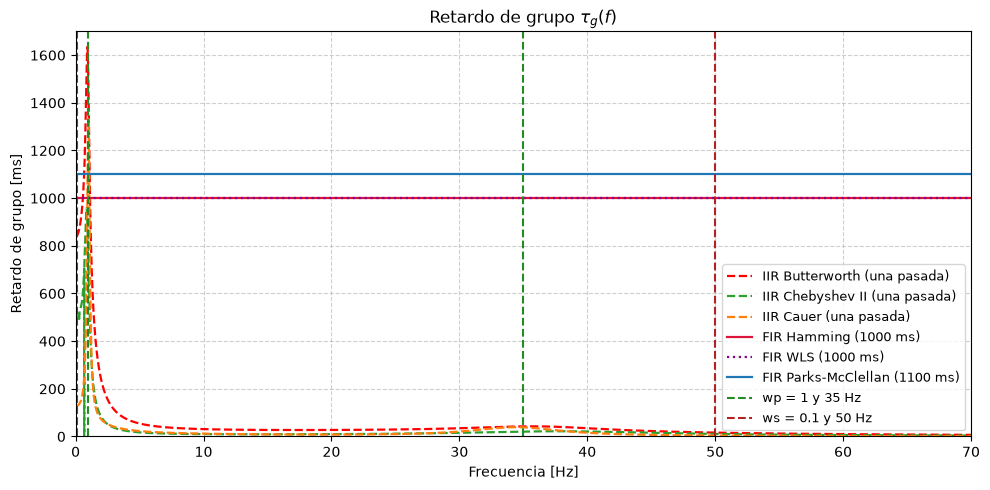

In [33]:

#%%
# 6. RETARDO DE GRUPO

# FIR de fase lineal: retardo constante = (numtaps - 1) / 2 muestras
retardo_hamm_ms = ((len(b_win_hamming) - 1) / 2) / fs_ecgconruido * 1000
retardo_wls_ms = ((len(b_wls) - 1) / 2) / fs_ecgconruido * 1000
retardo_remez_ms = ((len(b_remez) - 1) / 2) / fs_ecgconruido * 1000

# IIR: se suma el retardo de grupo de cada sección SOS (una sola pasada)
f_gd = np.linspace(0.05, 100, 20000)

def retardo_sos_ms(sos):
    """Retardo de grupo [ms] de una cascada SOS: suma del de cada sección."""
    retardo = np.zeros_like(f_gd)
    for seccion in sos:
        _, gd_seccion = signal.group_delay((seccion[:3], seccion[3:]), w=f_gd, fs=fs_ecgconruido)
        retardo += gd_seccion / fs_ecgconruido * 1000
    return retardo

retardo_butt_ms = retardo_sos_ms(sos_butt)
retardo_cheby_ms = retardo_sos_ms(sos_cheby)
retardo_elip_ms = retardo_sos_ms(sos_elip)

plt.figure(figsize=(10, 5))

plt.plot(f_gd, retardo_butt_ms, label="IIR Butterworth (una pasada)", color="red", linestyle="--", lw=1.6)
plt.plot(f_gd, retardo_cheby_ms, label="IIR Chebyshev II (una pasada)", color="tab:green", linestyle="--", lw=1.6)
plt.plot(f_gd, retardo_elip_ms, label="IIR Cauer (una pasada)", color="tab:orange", linestyle="--", lw=1.6)
plt.axhline(retardo_hamm_ms, label=f"FIR Hamming ({retardo_hamm_ms:.0f} ms)", color="crimson", lw=1.6)
plt.axhline(retardo_wls_ms, label=f"FIR WLS ({retardo_wls_ms:.0f} ms)", color="darkmagenta", lw=1.6, linestyle=":")
plt.axhline(retardo_remez_ms, label=f"FIR Parks-McClellan ({retardo_remez_ms:.0f} ms)", color="tab:blue", lw=1.6)

plt.axvline(wp[0], color="forestgreen", linestyle="--", label=f"wp = {wp[0]} y {wp[1]} Hz")
plt.axvline(wp[1], color="forestgreen", linestyle="--")
plt.axvline(ws[0], color="firebrick", linestyle="--", label=f"ws = {ws[0]} y {ws[1]} Hz")
plt.axvline(ws[1], color="firebrick", linestyle="--")

plt.xlim(0, 70)
plt.ylim(0, 1700)
plt.title(r"Retardo de grupo $\tau_g(f)$")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Retardo de grupo [ms]")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="best", fontsize=9)
plt.tight_layout()
plt.show()


**Figura 5.** Comparación del retardo de grupo de los filtros FIR Hamming, WLS y Parks-McClellan, y de los filtros IIR Butterworth, Chebyshev II y Cauer. Para los filtros IIR se representa el retardo correspondiente a una sola pasada.

**Análisis de los resultados**

En la Figura 5 se observa una diferencia clara entre el comportamiento del retardo de grupo de los filtros FIR e IIR diseñados.

Los filtros FIR Hamming y WLS presentan curvas horizontales superpuestas en 1000 ms, mientras que Parks-McClellan muestra un retardo constante de 1100 ms. Este comportamiento es coherente con la fase lineal de los tres filtros y con la simetría de sus respuestas impulsionales analizada anteriormente. La diferencia de 100 ms se debe a la mayor cantidad de coeficientes del filtro Parks-McClellan.

En cambio, los filtros IIR Butterworth, Chebyshev tipo II y Cauer presentan un retardo de grupo variable con la frecuencia, característico de sus respuestas de fase no lineal. En las frecuencias más bajas se observan valores elevados, especialmente para Butterworth, que disminuyen considerablemente al aumentar la frecuencia.

Dentro de gran parte de la banda de paso, los tres filtros IIR presentan retardos menores que los filtros FIR, aunque con variaciones según la frecuencia. Además, cerca del límite superior de 35 Hz se observa un incremento moderado del retardo, asociado a la transición hacia la banda de rechazo.

Es importante señalar que las curvas de los filtros IIR corresponden a una única pasada. En su aplicación sobre el ECG se utilizó `sosfiltfilt`, que realiza el filtrado en ambos sentidos temporales, obteniendo una respuesta efectiva de fase cero. Por lo tanto, los retardos representados caracterizan las aproximaciones IIR individuales, pero no corresponden al desplazamiento temporal neto de las señales finalmente procesadas.

En conjunto, el análisis permite comparar las características temporales de los seis filtros. Los FIR presentan un retardo constante y compensable, mientras que los IIR muestran una dependencia del retardo con la frecuencia en una sola pasada, cuyo efecto de fase se cancela mediante el filtrado bidireccional utilizado.

### Evaluación del filtrado en regiones con interferencias

Con el objetivo de evaluar la capacidad de los filtros para atenuar las perturbaciones presentes en el registro electrocardiográfico, se seleccionaron dos regiones de interés comprendidas entre las muestras 4000 y 5500, y entre las muestras 10000 y 11000, siguiendo los intervalos propuestos en la consigna.

En cada región se comparó la señal original con los resultados obtenidos mediante los seis filtros digitales diseñados: Butterworth, Chebyshev tipo II, Cauer, FIR Hamming, FIR WLS y FIR Parks-McClellan.

Para los filtros FIR se compensaron los retardos correspondientes a cada diseño, con el objetivo de alinear temporalmente las señales y facilitar la comparación de la morfología de los latidos. Los filtros IIR, por su parte, fueron aplicados mediante filtrado bidireccional, evitando un desplazamiento temporal neto asociado a su fase.

El análisis de estos segmentos permite evaluar cualitativamente la reducción de las irregularidades presentes en el trazado, el comportamiento de la línea de base y las posibles modificaciones introducidas sobre las ondas y los complejos característicos del ECG.

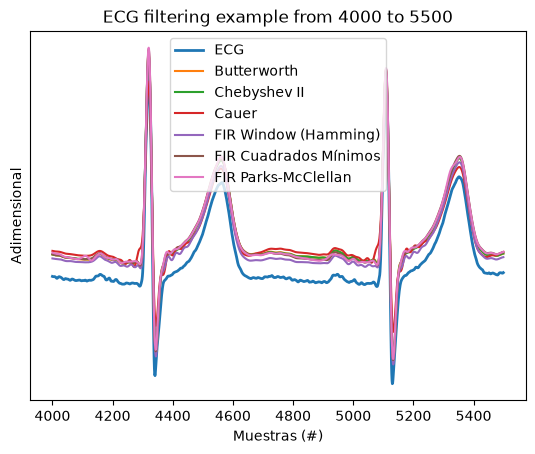

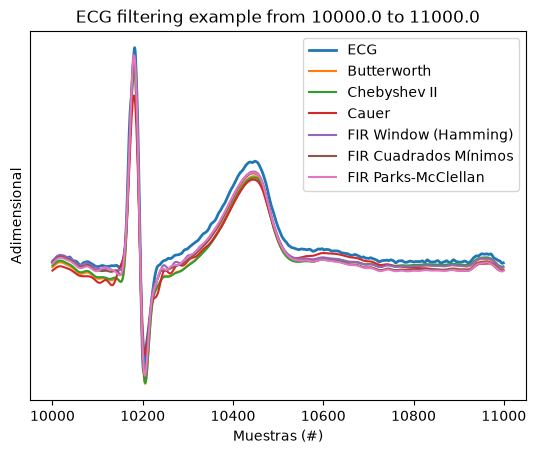

In [34]:

#%% Regiones de interés

cant_muestras = ecg_conruido.shape[0]

regs_interes = (
        [4000, 5500], # muestras
        [10e3, 11e3], # muestras
        )

for ii in regs_interes:

    # intervalo limitado de 0 a cant_muestras
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')

    plt.figure()
    plt.plot(zoom_region, ecg_conruido[zoom_region], label='ECG', linewidth=2)
    plt.plot(zoom_region, ecg_filt_butt[zoom_region], label='Butterworth')
    plt.plot(zoom_region, ecg_filt_cheby[zoom_region], label='Chebyshev II')
    plt.plot(zoom_region, ecg_filt_elip[zoom_region], label='Cauer')
    plt.plot(zoom_region, ecg_filt_winhamm[zoom_region + demora_hamm], label='FIR Window (Hamming)')
    plt.plot(zoom_region, ecg_filt_wls[zoom_region + demora_wls], label='FIR Cuadrados Mínimos')
    plt.plot(zoom_region, ecg_filt_remez[zoom_region + demora_remez], label='FIR Parks-McClellan')

    plt.title('ECG filtering example from ' + str(ii[0]) + ' to ' + str(ii[1]) )
    plt.ylabel('Adimensional')
    plt.xlabel('Muestras (#)')

    axes_hdl = plt.gca()
    axes_hdl.legend()
    axes_hdl.set_yticks(())

    plt.show()


**Figura 6.** Comparación entre el ECG original y las señales filtradas mediante los seis filtros digitales en la región comprendida entre las muestras 4000 y 5500.

**Figura 7.** Comparación entre el ECG original y las señales filtradas mediante los seis filtros digitales en la región comprendida entre las muestras 10000 y 11000.

### Análisis de los resultados en regiones con interferencias

En las Figuras 6 y 7 se presentan las comparaciones entre el ECG original y las señales obtenidas mediante los seis filtros digitales diseñados, considerando dos intervalos del registro seleccionados para evaluar la reducción de interferencias.

En la primera región, comprendida entre las muestras 4000 y 5500, se identifican dos complejos cardíacos de gran amplitud, acompañados de pequeñas irregularidades en el trazado original. Luego de aplicar los filtros, se observa una mayor suavidad de las señales, con una reducción de las oscilaciones de menor amplitud.

Los complejos principales conservan aproximadamente sus posiciones temporales, aunque se presentan modificaciones en las amplitudes de algunos picos y de las ondas más anchas. Además, se observa que las señales filtradas presentan diferencias en su nivel de referencia respecto del ECG original, por lo que no puede afirmarse que el desplazamiento de la línea de base haya sido eliminado completamente.

En la segunda región, comprendida entre las muestras 10000 y 11000, se observa un complejo QRS pronunciado seguido de una onda de mayor duración. Las señales filtradas mantienen la ubicación temporal de estas componentes y presentan trazados más suaves, indicando una reducción cualitativa de las irregularidades presentes en el registro.

Sin embargo, también se identifican disminuciones en la amplitud de algunos picos y de la onda posterior al complejo QRS. Esto indica que, además de atenuar las componentes interferentes, el filtrado puede modificar parcialmente las características del ECG.

Al comparar las distintas metodologías, se observa que los seis filtros presentan resultados relativamente semejantes en ambas regiones, aunque existen diferencias en los niveles de referencia y en las amplitudes de determinadas ondas.

En conjunto, el análisis permite observar una reducción cualitativa de las irregularidades del trazado y una conservación aproximada de la morfología general de los latidos. No obstante, las modificaciones identificadas muestran que el filtrado no resulta completamente inocuo sobre la señal y que su rendimiento debe evaluarse considerando tanto la atenuación del ruido como la preservación de las componentes cardíacas de interés.

### Evaluación del filtrado en regiones adicionales del registro

Con el objetivo de evaluar si los filtros producen modificaciones innecesarias sobre las componentes de interés del ECG, se seleccionaron tres regiones del registro con menor presencia esperada de interferencias, siguiendo los intervalos propuestos en la consigna.

Las regiones analizadas corresponden a los intervalos comprendidos entre los minutos 5 y 5,2; 12 y 12,4; y 15 y 15,2. Considerando una frecuencia de muestreo de 1000 Hz, estos segmentos corresponden a las muestras 300000–312000, 720000–744000 y 900000–912000, respectivamente.

En cada región se comparó la señal original con las obtenidas mediante los seis filtros digitales diseñados. Para los filtros FIR se compensaron los retardos de grupo correspondientes, permitiendo alinear temporalmente los complejos cardíacos con el ECG original.

Este análisis busca verificar la conservación de la morfología de los latidos, prestando especial atención a las amplitudes de los complejos QRS, las características de las ondas y el comportamiento de la línea de base.

De esta manera, se pretende determinar si los filtros permiten reducir las interferencias sin introducir modificaciones significativas en los segmentos del registro que presentan menor contaminación.

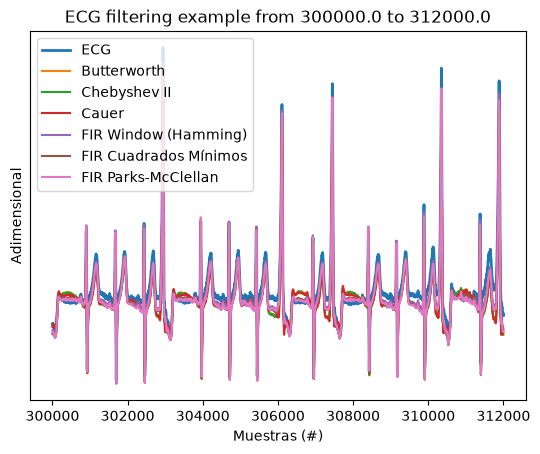

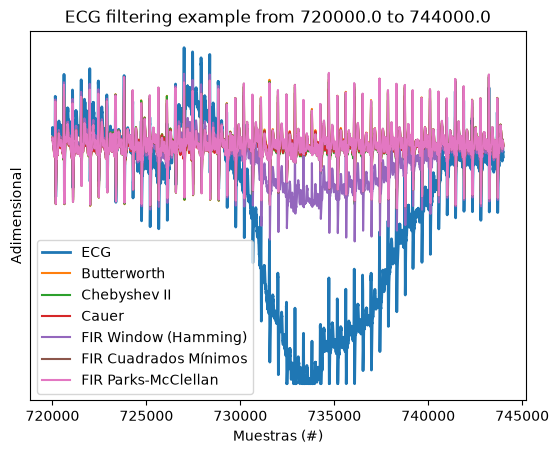

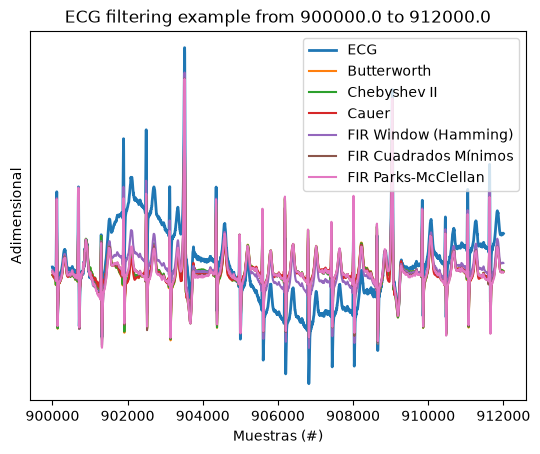

In [35]:

regs_interes = (
        np.array([5, 5.2]) *60*fs_ecgconruido, # minutos a muestras
        np.array([12, 12.4]) *60*fs_ecgconruido, # minutos a muestras
        np.array([15, 15.2]) *60*fs_ecgconruido, # minutos a muestras
        )

for ii in regs_interes:

    # intervalo limitado de 0 a cant_muestras
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')

    plt.figure()
    plt.plot(zoom_region, ecg_conruido[zoom_region], label='ECG', linewidth=2)
    plt.plot(zoom_region, ecg_filt_butt[zoom_region], label='Butterworth')
    plt.plot(zoom_region, ecg_filt_cheby[zoom_region], label='Chebyshev II')
    plt.plot(zoom_region, ecg_filt_elip[zoom_region], label='Cauer')
    plt.plot(zoom_region, ecg_filt_winhamm[zoom_region + demora_hamm], label='FIR Window (Hamming)')
    plt.plot(zoom_region, ecg_filt_wls[zoom_region + demora_wls], label='FIR Cuadrados Mínimos')
    plt.plot(zoom_region, ecg_filt_remez[zoom_region + demora_remez], label='FIR Parks-McClellan')

    plt.title('ECG filtering example from ' + str(ii[0]) + ' to ' + str(ii[1]) )
    plt.ylabel('Adimensional')
    plt.xlabel('Muestras (#)')

    axes_hdl = plt.gca()
    axes_hdl.legend()
    axes_hdl.set_yticks(())

    plt.show()


**Figura 8.** Comparación del ECG original y las señales filtradas mediante los seis filtros digitales en el intervalo comprendido entre los minutos 5 y 5,2.

**Figura 9.** Comparación del ECG original y las señales filtradas mediante los seis filtros digitales en el intervalo comprendido entre los minutos 12 y 12,4.

**Figura 10.** Comparación del ECG original y las señales filtradas mediante los seis filtros digitales en el intervalo comprendido entre los minutos 15 y 15,2.

En las Figuras 8, 9 y 10 se comparan el ECG original y las señales filtradas mediante los seis filtros digitales diseñados en tres regiones del registro propuestas en la consigna, correspondientes a los intervalos comprendidos entre los minutos 5 y 5,2; 12 y 12,4; y 15 y 15,2.

En la primera región, correspondiente al intervalo entre las muestras 300000 y 312000, se observa un comportamiento similar al analizado previamente en la comparación temporal general. Los complejos cardíacos mantienen aproximadamente sus posiciones temporales luego del filtrado, y los seis diseños producen una señal más suave que el registro original. Sin embargo, también se observan diferencias en la amplitud de algunos picos y en el nivel de referencia de ciertos segmentos, por lo que el filtrado no puede considerarse completamente inocuo sobre la señal.

En la segunda región, comprendida entre las muestras 720000 y 744000, el ECG original presenta una perturbación de gran amplitud y variación lenta, claramente visible en la línea de base. En este caso, los seis filtros atenúan de manera marcada esa componente de muy baja frecuencia, obteniéndose señales filtradas más próximas entre sí y con una reducción importante de la deriva presente en la señal original. No obstante, se observan diferencias entre los filtros FIR y los IIR, especialmente en la forma de las oscilaciones residuales y en el comportamiento del nivel de referencia.

En la tercera región, correspondiente a las muestras 900000 a 912000, también se identifican variaciones importantes del trazado original, junto con complejos cardíacos de amplitud elevada. Los filtros reducen las fluctuaciones lentas y suavizan el registro, aunque continúan observándose diferencias entre las señales filtradas y el ECG original, tanto en la amplitud de algunos complejos como en el nivel de referencia de distintos segmentos.

En conjunto, el análisis de estas regiones permite observar que los filtros logran reducir componentes de baja frecuencia y suavizar el trazado del ECG, especialmente cuando la señal original presenta derivas o perturbaciones evidentes. Sin embargo, también se comprueba que el filtrado introduce modificaciones en la amplitud de algunas ondas y en la forma general de ciertos segmentos, por lo que su efecto no resulta completamente inocuo.

Estos resultados refuerzan la idea de que el diseño del filtrado implica un compromiso entre la atenuación de las interferencias y la preservación de la morfología de la señal electrocardiográfica. En términos cualitativos, los seis filtros muestran un comportamiento comparable, aunque con diferencias en la manera en que modifican la línea de base y las amplitudes de algunos complejos.

# Conclusión

En este trabajo se diseñaron y aplicaron seis filtros digitales, tres IIR y tres FIR, con el objetivo de reducir las interferencias presentes en un registro electrocardiográfico obtenido durante una prueba de esfuerzo, procurando conservar la morfología de los latidos.

A partir del análisis espectral realizado previamente se estableció una plantilla pasabanda orientada a atenuar tanto las variaciones lentas de la línea de base como las componentes de alta frecuencia asociadas al ruido. Sobre esa base, se implementaron los filtros IIR Butterworth, Chebyshev tipo II y Cauer, y los filtros FIR diseñados mediante ventana Hamming, cuadrados mínimos ponderados y Parks-McClellan.

El análisis de las respuestas en frecuencia permitió observar que los seis diseños presentan el comportamiento pasabanda buscado, aunque con diferencias en la planicidad de la banda de paso, en la pendiente de las transiciones y en el nivel de atenuación alcanzado en las bandas de rechazo. En particular, los filtros FIR mostraron retardos de grupo constantes, mientras que los IIR presentaron retardos dependientes de la frecuencia para una sola pasada. En la implementación sobre el ECG, estas diferencias se resolvieron mediante la compensación del retardo en los FIR y el uso de filtrado bidireccional en los IIR.

La evaluación temporal sobre distintas regiones del registro mostró que los filtros permiten suavizar el trazado y reducir cualitativamente tanto las irregularidades de alta frecuencia como ciertas variaciones lentas de la línea de base. Esto se observó con especial claridad en las regiones donde el ECG original presentaba derivas o perturbaciones más evidentes.

Sin embargo, también se comprobó que el filtrado introduce modificaciones en la amplitud de algunos complejos y en el nivel de referencia de ciertos segmentos. Por lo tanto, si bien los filtros resultan eficaces para atenuar interferencias, no puede considerarse que su acción sea completamente inocua sobre la señal.

En términos generales, los seis filtros mostraron un desempeño cualitativamente adecuado y comparable, con diferencias asociadas a sus respectivas metodologías de diseño. En consecuencia, la elección de un filtro no depende únicamente de su capacidad para atenuar el ruido, sino también del grado de conservación de la morfología del ECG, del retardo introducido y del tipo de implementación utilizado.

En síntesis, el trabajo permitió verificar que el filtrado digital constituye una herramienta efectiva para mejorar la calidad del registro electrocardiográfico, aunque su aplicación requiere considerar cuidadosamente el compromiso entre reducción de interferencias y preservación de la información fisiológicamente relevante.